# Data Preparation for Modeling
**Project:** Energy Efficient AI  |  **Input:** `../data/clean_data.csv`  |  **Target:** `efficiency_class` (3 classes)

**Goal:** take the clean dataset and prepare it end to end so it is ready for a Machine Learning model.

| Requirement | Where it is done |
|---|---|
| Category columns are encoded correctly | Step 3 |
| Numeric columns are scaled appropriately | Step 5 |
| The dataset is split into train and test sets | Step 4 |
| No leakage exists between the two sets | Step 6 |

**Order of work (this order prevents leakage):** select features, encode the target, **split first**, then scale (learning only from the train set), then check for leakage, then save.

## Step 0: Setup

In [1]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Folders for charts and for the prepared data
os.makedirs("figures", exist_ok=True)
os.makedirs("../data/prepared", exist_ok=True)

# Settings (change them here if needed)
RANDOM_STATE = 42           # same number = same split every time we run the notebook
TEST_SIZE = 0.2             # 80% train, 20% test
DROP_SUSPECT_FEATURES = []  # example: ["energy_consumption_kwh"] (see Steps 6.2 to 6.4 before using it)

## Step 1: Load the clean dataset

In [2]:
# Load the clean dataset created in Milestone 2
df = pd.read_csv("../data/clean_data.csv")
print(f"Clean dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

Clean dataset: 7167 rows, 11 columns
Missing values: 0


,system_load_level,power_draw_watts,memory_usage_mb,cpu_utilization_percent,gpu_utilization_percent,execution_time_ms,throughput_ops_per_sec,energy_consumption_kwh,thermal_output_c,resource_utilization_index,efficiency_class
0,0.822379,172.758993,8484.416855,63.501764,7.461321,351.589068,1368.291944,2.572335,43.106626,0.438742,Moderate_Efficiency
1,0.816021,285.086823,4149.960984,22.421314,68.842454,431.508959,1356.261452,9.753689,74.457810,0.419990,Low_Efficiency
2,0.448547,107.840571,695.421292,84.388839,43.996473,428.200098,212.917860,5.877830,64.245964,0.814711,Moderate_Efficiency
3,0.859491,151.089436,13895.010522,68.329937,84.417851,154.048529,391.544439,6.560060,86.402010,0.987481,Low_Efficiency
4,0.540144,128.592669,10915.551614,64.706458,80.707858,189.069332,268.652949,8.338474,53.439116,0.751681,Low_Efficiency


## Step 2: Choose the features and the target

In [3]:
# Separate the target (what we predict) from the features (what the model sees)
target = "efficiency_class"
feature_cols = [c for c in df.columns if c != target]

# Are there any text (category) columns among the features?
text_features = df[feature_cols].select_dtypes(exclude="number").columns.tolist()
print("Number of features:", len(feature_cols))
print("Text (category) feature columns:", text_features)

Number of features: 10
Text (category) feature columns: []


In [4]:
# Check if any two features are almost the same (redundant features)
corr = df[feature_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("Highest correlation between two features:")
print(pairs.head(3).round(3).to_string())

Highest correlation between two features:
thermal_output_c   resource_utilization_index    0.028
system_load_level  thermal_output_c              0.027
                   throughput_ops_per_sec        0.025


In [5]:
# Decision: keep all 10 measurement columns as features
# Reason: the highest correlation between any two features is very small (about 0.03),
# so no feature repeats another one, and none can be removed as redundant.

# Decision: do not create new (engineered) features for now
# Reason: we have no confirmed domain rule yet that a new column would add useful information.
# We can add engineered features later if the model needs them.

# Apply the optional drop list (it is empty by default)
feature_cols = [c for c in feature_cols if c not in DROP_SUSPECT_FEATURES]
X = df[feature_cols]
print("Features used:", len(feature_cols))

Features used: 10


## Step 3: Encode the category column (the target)

In [6]:
# Decision: encode the target with a label map that keeps the natural order
# Reason: the classes have an order (Low < Moderate < High), so numbers 0, 1, 2 make sense.
# Decision: no encoding for the features, because all of them are already numeric.
target_map = {"Low_Efficiency": 0, "Moderate_Efficiency": 1, "High_Efficiency": 2}
y = df[target].map(target_map)
assert y.notna().all()   # every label was found in the map

mapping_table = pd.DataFrame({
    "label": list(target_map.keys()),
    "code": list(target_map.values()),
    "rows": [int((y == v).sum()) for v in target_map.values()],
})
mapping_table

,label,code,rows
0,Low_Efficiency,0,2972
1,Moderate_Efficiency,1,3619
2,High_Efficiency,2,576


## Step 4: Split into train and test sets (before any scaling)

In [7]:
# Decision: split 80% train / 20% test, and use stratify=y
# Reason: High_Efficiency is only 8% of the data. Stratify keeps the same class percentages
# in both sets, so the test set is a fair copy of the real data.
# Decision: split BEFORE scaling, so the test set cannot influence the scaler (prevents leakage).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

proportions = pd.DataFrame({
    "All data": y.value_counts(normalize=True).sort_index(),
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index(),
}).mul(100).round(2)
proportions.index = ["Low (0)", "Moderate (1)", "High (2)"]
proportions

Train: (5733, 10) | Test: (1434, 10)


,All data,Train,Test
Low (0),41.47,41.46,41.49
Moderate (1),50.50,50.50,50.49
High (2),8.04,8.04,8.02


## Step 5: Scale the numeric columns (learning only from the train set)

In [8]:
# Decision: use StandardScaler (mean 0, standard deviation 1)
# Reason: the columns have very different sizes (memory is in thousands, load is between 0 and 1).
# Distance-based and gradient-based models (KNN, SVM, logistic regression, neural networks)
# would otherwise treat the large columns as more important. There are no outliers, so
# standardizing is safe.
scaler = StandardScaler()
scaler.fit(X_train)      # learn the mean and std from the TRAIN set only

# Apply the same mean and std to both sets
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=feature_cols, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

scaling_summary = pd.DataFrame({
    "train mean (before)": X_train.mean(),
    "train std (before)": X_train.std(),
    "train mean (after)": X_train_s.mean(),
    "train std (after)": X_train_s.std(),
}).round(3)
scaling_summary

,train mean (before),train std (before),train mean (after),train std (after)
system_load_level,0.546,0.259,0.0,1.0
power_draw_watts,198.624,86.610,-0.0,1.0
memory_usage_mb,8532.807,4555.364,0.0,1.0
cpu_utilization_percent,55.011,25.807,0.0,1.0
gpu_utilization_percent,49.775,28.787,-0.0,1.0
execution_time_ms,255.501,142.318,0.0,1.0
throughput_ops_per_sec,1014.940,566.577,0.0,1.0
energy_consumption_kwh,5.083,2.848,-0.0,1.0
thermal_output_c,59.866,17.319,-0.0,1.0
resource_utilization_index,0.601,0.229,0.0,1.0


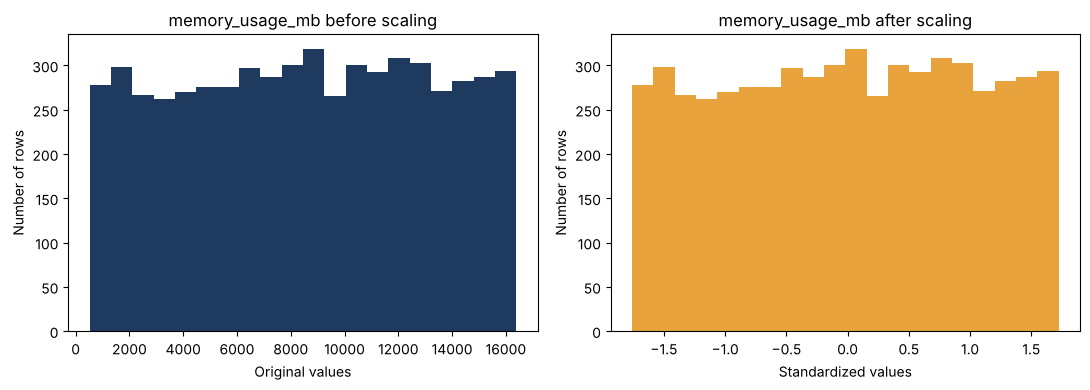

In [9]:
# Chart: one column before and after scaling (the shape stays the same, only the scale changes)
demo_col = "memory_usage_mb" if "memory_usage_mb" in feature_cols else feature_cols[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(X_train[demo_col], bins=20, color="#1E3A5F")
axes[0].set_title(f"{demo_col} before scaling")
axes[0].set_xlabel("Original values")
axes[0].set_ylabel("Number of rows")
axes[1].hist(X_train_s[demo_col], bins=20, color="#E8A33D")
axes[1].set_title(f"{demo_col} after scaling")
axes[1].set_xlabel("Standardized values")
axes[1].set_ylabel("Number of rows")
plt.tight_layout()
plt.savefig("figures/scaling_before_after.png", dpi=120)
plt.show()

## Step 6: Check for leakage

### 6.1 Leakage between the train set and the test set

In [10]:
# Run a list of checks. Every check must PASS.
checks = []
def add(name, ok, detail):
    checks.append({"Check": name, "Result": "PASS" if ok else "FAIL", "Detail": detail})

# The scaler learned from train only: scaled train has mean 0, scaled test does not
train_mean0 = bool(np.allclose(X_train_s.mean(), 0, atol=1e-9))
test_mean0 = bool(np.allclose(X_test_s.mean(), 0, atol=1e-9))
add("Scaler learned from train only", train_mean0 and not test_mean0,
    f"scaled train mean is 0; scaled test mean is not exactly 0 (max {X_test_s.mean().abs().max():.3f})")

# No row appears in both sets (same row number)
same_index = len(set(X_train.index) & set(X_test.index))
add("No shared rows (by row number)", same_index == 0, f"{same_index} shared row numbers")

# No identical measurements appear in both sets
same_values = len(X_train.merge(X_test, how="inner"))
add("No identical rows across sets", same_values == 0, f"{same_values} identical rows")

# The target and the id are not inside the features
add("Target and id are not features", target not in X.columns and "id" not in X.columns,
    "feature columns: " + str(len(X.columns)))

# Nothing was lost or added by the split
add("Train + test = all rows", len(X_train) + len(X_test) == len(df),
    f"{len(X_train)} + {len(X_test)} = {len(df)}")

# Class percentages are the same in train and test
max_gap = float((proportions["Train"] - proportions["Test"]).abs().max())
add("Class percentages are similar", max_gap < 1.0, f"largest gap between train and test: {max_gap:.2f} points")

# No missing values were created
missing_after = int(X_train_s.isnull().sum().sum() + X_test_s.isnull().sum().sum())
add("No missing values after scaling", missing_after == 0, f"{missing_after} missing values")

leakage_report = pd.DataFrame(checks)
assert (leakage_report["Result"] == "PASS").all()
leakage_report

,Check,Result,Detail
0,Scaler learned from train only,PASS,scaled train mean is 0; scaled test mean is no...
1,No shared rows (by row number),PASS,0 shared row numbers
2,No identical rows across sets,PASS,0 identical rows
3,Target and id are not features,PASS,feature columns: 10
4,Train + test = all rows,PASS,5733 + 1434 = 7167
5,Class percentages are similar,PASS,largest gap between train and test: 0.03 points
6,No missing values after scaling,PASS,0 missing values


### 6.2 Leakage between the features and the target

In [11]:
# A different kind of leakage: a feature that gives away the answer too easily.
# We train a small decision tree on ONE feature at a time (train set) and test it (test set).
rows = []
for c in feature_cols:
    m = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train[[c]], y_train)
    p = m.predict(X_test[[c]])
    rows.append({"feature": c,
                 "accuracy": accuracy_score(y_test, p),
                 "macro_F1": f1_score(y_test, p, average="macro")})
single_feature = pd.DataFrame(rows).sort_values("accuracy", ascending=False).round(3).reset_index(drop=True)

# Baseline: always predict the biggest class
baseline = float((y_test == y_train.mode()[0]).mean())

# All features together, with a small tree
all_model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE).fit(X_train, y_train)
p_all = all_model.predict(X_test)

print(f"Baseline (always predict the biggest class): accuracy {baseline:.3f}")
print(f"All features, small tree (depth 4): accuracy {accuracy_score(y_test, p_all):.3f}, macro F1 {f1_score(y_test, p_all, average='macro'):.3f}")
single_feature

Baseline (always predict the biggest class): accuracy 0.505
All features, small tree (depth 4): accuracy 0.999, macro F1 0.998


,feature,accuracy,macro_F1
0,energy_consumption_kwh,0.920,0.642
1,execution_time_ms,0.531,0.342
2,power_draw_watts,0.508,0.252
3,resource_utilization_index,0.506,0.250
4,cpu_utilization_percent,0.506,0.228
5,gpu_utilization_percent,0.505,0.228
6,thermal_output_c,0.502,0.226
7,system_load_level,0.501,0.234
8,throughput_ops_per_sec,0.500,0.224
9,memory_usage_mb,0.497,0.261


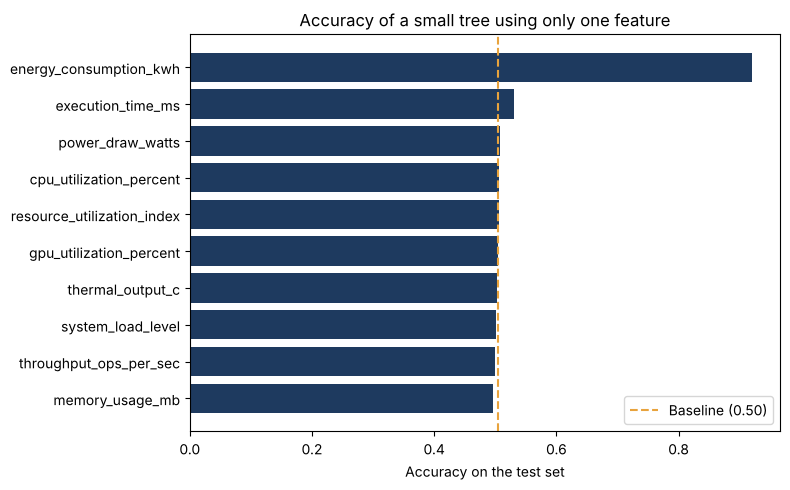

In [12]:
# Chart: how well can ONE feature predict the class?
order = single_feature.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(order["feature"], order["accuracy"], color="#1E3A5F")
ax.axvline(baseline, color="#E8A33D", linestyle="--", label=f"Baseline ({baseline:.2f})")
ax.set_title("Accuracy of a small tree using only one feature")
ax.set_xlabel("Accuracy on the test set")
ax.legend()
plt.tight_layout()
plt.savefig("figures/single_feature_check.png", dpi=120)
plt.show()

**What this shows (with the default settings):**

- With the same simple tree, almost every feature scores about **0.50**, which is the same as the baseline. These features alone cannot predict the class.
- `energy_consumption_kwh` alone reaches about **0.92** accuracy, and `execution_time_ms` adds a small signal.
- Using all features, a very small tree reaches about **0.999** accuracy.

This suggests the class may be **defined by a rule** on these two columns. The next steps test this idea.

### 6.3 Is the class a simple rule?

In [13]:
# Let a very small decision tree (3 levels) use only the two suspect columns and show what it learned
rule_cols = [c for c in ["energy_consumption_kwh", "execution_time_ms"] if c in feature_cols]
rule_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train[rule_cols], y_train)

print("Class codes: 0 = Low, 1 = Moderate, 2 = High")
print(export_text(rule_tree, feature_names=rule_cols))

Class codes: 0 = Low, 1 = Moderate, 2 = High
|--- energy_consumption_kwh <= 6.00
|   |--- execution_time_ms <= 150.00
|   |   |--- energy_consumption_kwh <= 3.00
|   |   |   |--- class: 2
|   |   |--- energy_consumption_kwh >  3.00
|   |   |   |--- class: 1
|   |--- execution_time_ms >  150.00
|   |   |--- class: 1
|--- energy_consumption_kwh >  6.00
|   |--- class: 0


In [14]:
# Write the rule by hand and compare it with the real class for ALL rows
energy = df["energy_consumption_kwh"]
time_ms = df["execution_time_ms"]
rule_prediction = np.where(energy > 6, 0,                                    # high energy -> Low
                  np.where((time_ms <= 150) & (energy <= 3), 2, 1))          # fast and low energy -> High, else Moderate

agreement = float((rule_prediction == y).mean())
print(f"The hand-written rule matches the real class in {agreement:.1%} of all {len(df)} rows")
pd.crosstab(pd.Series(rule_prediction, index=df.index, name="rule says"), y.rename("real class"))

The hand-written rule matches the real class in 100.0% of all 7167 rows


real class,0,1,2
rule says,,,
0,2972,0,0
1,0,3619,0
2,0,0,576


**The rule we found:**

| Condition | Class |
|---|---|
| `energy_consumption_kwh` > 6 | Low_Efficiency |
| `energy_consumption_kwh` <= 3 **and** `execution_time_ms` <= 150 | High_Efficiency |
| Everything else | Moderate_Efficiency |

This rule matches **all 7,167 rows (100%)**. The limits (6, 3, and 150) are round numbers, which suggests the dataset is synthetic and the class was created from these two columns.
This conclusion comes from checking the data, not from the dataset documentation.

### 6.4 Four experiments: what happens with and without the two rule columns?

In [15]:
# Train a Random Forest (200 trees) on four different sets of features and test it on the test set
def run_experiment(name, cols):
    model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    return {"Features used": name,
            "Number of features": len(cols),
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, average="macro"),
            "F1 of High class": f1_score(y_test, pred, average=None, labels=[0, 1, 2])[2]}

without_energy = [c for c in feature_cols if c != "energy_consumption_kwh"]
without_both = [c for c in feature_cols if c not in rule_cols]

experiments = pd.DataFrame([
    run_experiment("1. All features", feature_cols),
    run_experiment("2. Only the two rule columns", rule_cols),
    run_experiment("3. Without energy_consumption_kwh", without_energy),
    run_experiment("4. Without both rule columns", without_both),
]).round(3)
print(f"Baseline (always predict the biggest class): accuracy {baseline:.3f}")
experiments

Baseline (always predict the biggest class): accuracy 0.505


,Features used,Number of features,Accuracy,Macro F1,F1 of High class
0,1. All features,10,0.999,0.998,0.996
1,2. Only the two rule columns,2,0.999,0.998,0.996
2,3. Without energy_consumption_kwh,9,0.512,0.396,0.192
3,4. Without both rule columns,8,0.474,0.305,0.000


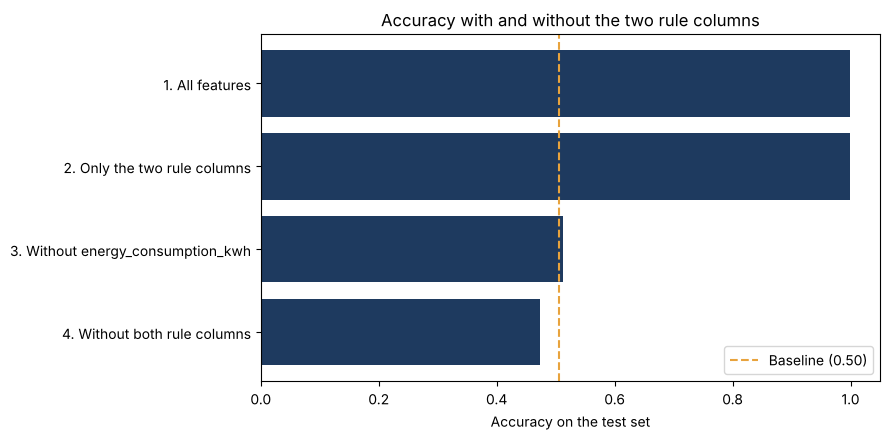

In [16]:
# Chart: accuracy of the four experiments
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(experiments["Features used"][::-1], experiments["Accuracy"][::-1], color="#1E3A5F")
ax.axvline(baseline, color="#E8A33D", linestyle="--", label=f"Baseline ({baseline:.2f})")
ax.set_title("Accuracy with and without the two rule columns")
ax.set_xlabel("Accuracy on the test set")
ax.set_xlim(0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/four_experiments.png", dpi=120)
plt.show()

**What the four experiments show:**

- The **two rule columns alone** give the same score as all features. The other 8 columns add nothing.
- **Without `energy_consumption_kwh`**, the model drops to about the baseline (guessing the biggest class) and finds the High class rarely.
- **Without both rule columns**, the model is worse than the baseline and **never finds the High class** (F1 = 0).

**Meaning:** a model with these columns looks almost perfect only because it **rediscovers the rule that created the class**, not because it learned something about energy efficiency.
The other 8 columns do not carry information about the class in this dataset.

## Step 7: Save the prepared data

In [17]:
# Save the prepared sets (features are scaled; target is encoded as 0, 1, 2)
X_train_s.to_csv("../data/prepared/X_train.csv", index=False)
X_test_s.to_csv("../data/prepared/X_test.csv", index=False)
y_train.to_frame("efficiency_class").to_csv("../data/prepared/y_train.csv", index=False)
y_test.to_frame("efficiency_class").to_csv("../data/prepared/y_test.csv", index=False)

# Save the scaler numbers, so the same scaling can be applied to new data later
pd.DataFrame({"feature": feature_cols, "mean": scaler.mean_, "std": scaler.scale_}).to_csv(
    "../data/prepared/scaler_params.csv", index=False)

# Reload the files to confirm they were saved correctly
check = {name: pd.read_csv(f"../data/prepared/{name}.csv") for name in ["X_train", "X_test", "y_train", "y_test"]}
for name, frame in check.items():
    print(f"{name}.csv: {frame.shape[0]} rows, {frame.shape[1]} columns, missing values: {int(frame.isnull().sum().sum())}")

X_train.csv: 5733 rows, 10 columns, missing values: 0
X_test.csv: 1434 rows, 10 columns, missing values: 0
y_train.csv: 5733 rows, 1 columns, missing values: 0
y_test.csv: 1434 rows, 1 columns, missing values: 0


## Step 8: Summary

In [18]:
summary = pd.DataFrame({
    "Item": ["Rows in clean data", "Features used", "Train rows", "Test rows",
             "Encoded target classes", "Scaler", "Random state",
             "Leakage checks passed"],
    "Value": [len(df), len(feature_cols), len(X_train), len(X_test),
              "Low=0, Moderate=1, High=2", "StandardScaler (fit on train only)", RANDOM_STATE,
              f"{int((leakage_report['Result'] == 'PASS').sum())} of {len(leakage_report)}"],
})
summary

,Item,Value
0,Rows in clean data,7167
1,Features used,10
2,Train rows,5733
3,Test rows,1434
4,Encoded target classes,"Low=0, Moderate=1, High=2"
5,Scaler,StandardScaler (fit on train only)
6,Random state,42
7,Leakage checks passed,7 of 7


## Our proposal for modeling (Milestone 4)

1. **Keep all 10 features in the prepared files.** Nothing is hidden or removed.
2. **Train every model twice**: once with all features, and once without the two rule columns, and report both results.
3. **Report honestly:** with the rule columns the accuracy is about 99.9% because the model rediscovers the rule; without them it is about 51%, close to guessing.
4. **Ask the coach** (and check the dataset page) how the class `efficiency_class` was defined, to confirm the rule.

To run the "without energy" option in the whole notebook, set `DROP_SUSPECT_FEATURES = ["energy_consumption_kwh"]` in Step 0 and run all cells again.